<!-- This code runs a GLM analysis to analyze correlation between motoneurons over days -->

GLM ANALYSIS - Runs a GLM with spike or force data to understand correlations between motoneurons

In [8]:
import os
import re  
import math
import pickle
import zipfile
from collections import defaultdict
import sys
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import Normalize
from mpl_toolkits.mplot3d import Axes3D  

import h5py
from scipy import signal
from scipy.stats import (zscore, ks_2samp, linregress, pearsonr)
from scipy.signal import (convolve, windows, resample)
from scipy.ndimage import gaussian_filter1d

from sklearn.preprocessing import (PolynomialFeatures, StandardScaler)
from sklearn.model_selection import (train_test_split, cross_val_score, KFold,GridSearchCV)


from scipy.signal import convolve, windows
from scipy.sparse import csr_matrix
from sklearn.model_selection import train_test_split
from pyglmnet import GLM


from sklearn.linear_model import PoissonRegressor
from sklearn.pipeline import make_pipeline
from scipy.interpolate import interp1d

from scipy.special import gammaln

from scipy.stats import poisson, chisquare


In [11]:
session_files1 = {
    "Day01": [
        'E3_MB01_Day01High_1.pkl', 'E3_MB01_Day01High_11.pkl', 'E3_MB01_Day01High_14.pkl',
        'E3_MB01_Day01High_17.pkl', 'E3_MB01_Day01High_21.pkl', 'E3_MB01_Day01High_24.pkl',
        'E3_MB01_Day01High_27.pkl', 'E3_MB01_Day01High_30.pkl', 'E3_MB01_Day01High_6.pkl',
        'E3_MB01_Day01High_9.pkl'
    ],
    "Day03": [
        'E3_MB01_Day03High_11.pkl', 'E3_MB01_Day03High_14.pkl', 'E3_MB01_Day03High_18.pkl',
        'E3_MB01_Day03High_21.pkl', 'E3_MB01_Day03High_23.pkl', 'E3_MB01_Day03High_26.pkl',
        'E3_MB01_Day03High_29.pkl', 'E3_MB01_Day03High_3.pkl', 'E3_MB01_Day03High_4.pkl',
        'E3_MB01_Day03High_9.pkl'
    ],
    "Day04": [
        'E3_MB01_Day04High_1.pkl', 'E3_MB01_Day04High_10.pkl', 'E3_MB01_Day04High_13.pkl',
        'E3_MB01_Day04High_17.pkl', 'E3_MB01_Day04High_20.pkl', 'E3_MB01_Day04High_23.pkl',
        'E3_MB01_Day04High_25.pkl', 'E3_MB01_Day04High_29.pkl', 'E3_MB01_Day04High_30.pkl',
        'E3_MB01_Day04High_6.pkl', 'E3_MB01_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB01_Day05High_1.pkl', 'E3_MB01_Day05High_10.pkl', 'E3_MB01_Day05High_13.pkl',
        'E3_MB01_Day05High_18.pkl', 'E3_MB01_Day05High_21.pkl', 'E3_MB01_Day05High_23.pkl',
        'E3_MB01_Day05High_26.pkl', 'E3_MB01_Day05High_28.pkl', 'E3_MB01_Day05High_5.pkl',
        'E3_MB01_Day05High_9.pkl'
    ],
    "Day06": [
        'E3_MB01_Day06High_10.pkl', 'E3_MB01_Day06High_14.pkl', 'E3_MB01_Day06High_18.pkl',
        'E3_MB01_Day06High_21.pkl', 'E3_MB01_Day06High_22.pkl', 'E3_MB01_Day06High_26.pkl',
        'E3_MB01_Day06High_3.pkl', 'E3_MB01_Day06High_30.pkl', 'E3_MB01_Day06High_5.pkl',
        'E3_MB01_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB01_Day07High_1.pkl', 'E3_MB01_Day07High_10.pkl', 'E3_MB01_Day07High_14.pkl',
        'E3_MB01_Day07High_18.pkl', 'E3_MB01_Day07High_19.pkl', 'E3_MB01_Day07High_23.pkl',
        'E3_MB01_Day07High_26.pkl', 'E3_MB01_Day07High_28.pkl', 'E3_MB01_Day07High_5.pkl',
        'E3_MB01_Day07High_9.pkl'
        
    ],
    
    "Day08": ['E3_MB01_Day08High_12.pkl', 'E3_MB01_Day08High_13.pkl', 'E3_MB01_Day08High_17.pkl',
              'E3_MB01_Day08High_21.pkl', 'E3_MB01_Day08High_23.pkl', 'E3_MB01_Day08High_25.pkl',
              'E3_MB01_Day08High_3.pkl', 'E3_MB01_Day08High_30.pkl', 'E3_MB01_Day08High_7.pkl'],
    "Day09": ['E3_MB01_Day09High_1.pkl', 'E3_MB01_Day09High_13.pkl', 'E3_MB01_Day09High_15.pkl',
              'E3_MB01_Day09High_18.pkl', 'E3_MB01_Day09High_23.pkl', 'E3_MB01_Day09High_26.pkl',
              'E3_MB01_Day09High_27.pkl', 'E3_MB01_Day09High_4.pkl', 'E3_MB01_Day09High_8.pkl',
              'E3_MB01_Day09High_9.pkl'],
    "Day10": ['E3_MB01_Day10High_1.pkl', 'E3_MB01_Day10High_10.pkl', 'E3_MB01_Day10High_15.pkl',
              'E3_MB01_Day10High_18.pkl', 'E3_MB01_Day10High_19.pkl', 'E3_MB01_Day10High_22.pkl',
              'E3_MB01_Day10High_25.pkl', 'E3_MB01_Day10High_30.pkl', 'E3_MB01_Day10High_5.pkl',
              'E3_MB01_Day10High_7.pkl'],
    "Day11": ['E3_MB01_Day11High_12.pkl', 'E3_MB01_Day11High_15.pkl', 'E3_MB01_Day11High_18.pkl',
              'E3_MB01_Day11High_20.pkl', 'E3_MB01_Day11High_24.pkl', 'E3_MB01_Day11High_25.pkl',
              'E3_MB01_Day11High_28.pkl', 'E3_MB01_Day11High_3.pkl', 'E3_MB01_Day11High_4.pkl',
              'E3_MB01_Day11High_8.pkl'],
    "Day12": ['E3_MB01_Day12High_12.pkl', 'E3_MB01_Day12High_15.pkl', 'E3_MB01_Day12High_17.pkl',
              'E3_MB01_Day12High_2.pkl', 'E3_MB01_Day12High_20.pkl', 'E3_MB01_Day12High_24.pkl',
              'E3_MB01_Day12High_25.pkl', 'E3_MB01_Day12High_28.pkl', 'E3_MB01_Day12High_4.pkl',
              'E3_MB01_Day12High_7.pkl'],
    "Day13": ['E3_MB01_Day13High_1.pkl', 'E3_MB01_Day13High_12.pkl', 'E3_MB01_Day13High_14.pkl',
              'E3_MB01_Day13High_16.pkl', 'E3_MB01_Day13High_19.pkl', 'E3_MB01_Day13High_23.pkl',
              'E3_MB01_Day13High_25.pkl', 'E3_MB01_Day13High_30.pkl', 'E3_MB01_Day13High_5.pkl',
              'E3_MB01_Day13High_9.pkl'],
    "Day14": ['E3_MB01_Day14High_12.pkl', 'E3_MB01_Day14High_15.pkl', 'E3_MB01_Day14High_18.pkl',
              'E3_MB01_Day14High_19.pkl', 'E3_MB01_Day14High_22.pkl', 'E3_MB01_Day14High_26.pkl',
              'E3_MB01_Day14High_28.pkl', 'E3_MB01_Day14High_3.pkl', 'E3_MB01_Day14High_5.pkl',
              'E3_MB01_Day14High_8.pkl']

}



#######################





session_files3 = {
    "Day01": ['E3_MB03_Day01High_12.pkl', 'E3_MB03_Day01High_14.pkl', 'E3_MB03_Day01High_16.pkl',
              'E3_MB03_Day01High_19.pkl', 'E3_MB03_Day01High_23.pkl', 'E3_MB03_Day01High_27.pkl',
              'E3_MB03_Day01High_29.pkl', 'E3_MB03_Day01High_3.pkl', 'E3_MB03_Day01High_4.pkl',
              'E3_MB03_Day01High_8.pkl'],
    "Day02": ['E3_MB03_Day02High_12.pkl', 'E3_MB03_Day02High_15.pkl', 'E3_MB03_Day02High_17.pkl',
              'E3_MB03_Day02High_19.pkl', 'E3_MB03_Day02High_2.pkl', 'E3_MB03_Day02High_24.pkl',
              'E3_MB03_Day02High_26.pkl', 'E3_MB03_Day02High_29.pkl', 'E3_MB03_Day02High_6.pkl',
              'E3_MB03_Day02High_8.pkl'],
    "Day03": ['E3_MB03_Day03High_10.pkl', 'E3_MB03_Day03High_15.pkl', 'E3_MB03_Day03High_17.pkl',
              'E3_MB03_Day03High_2.pkl', 'E3_MB03_Day03High_21.pkl', 'E3_MB03_Day03High_23.pkl',
              'E3_MB03_Day03High_26.pkl', 'E3_MB03_Day03High_29.pkl', 'E3_MB03_Day03High_5.pkl',
              'E3_MB03_Day03High_9.pkl'],
    "Day04": ['E3_MB03_Day04High_1.pkl', 'E3_MB03_Day04High_11.pkl', 'E3_MB03_Day04High_15.pkl',
              'E3_MB03_Day04High_16.pkl', 'E3_MB03_Day04High_20.pkl', 'E3_MB03_Day04High_23.pkl',
              'E3_MB03_Day04High_26.pkl', 'E3_MB03_Day04High_28.pkl', 'E3_MB03_Day04High_4.pkl',
              'E3_MB03_Day04High_9.pkl'],
    "Day05": ['E3_MB03_Day05High_12.pkl', 'E3_MB03_Day05High_15.pkl', 'E3_MB03_Day05High_17.pkl',
              'E3_MB03_Day05High_20.pkl', 'E3_MB03_Day05High_22.pkl', 'E3_MB03_Day05High_26.pkl',
              'E3_MB03_Day05High_29.pkl', 'E3_MB03_Day05High_3.pkl', 'E3_MB03_Day05High_4.pkl',
              'E3_MB03_Day05High_7.pkl'],
    "Day07": ['E3_MB03_Day07High_11.pkl', 'E3_MB03_Day07High_13.pkl', 'E3_MB03_Day07High_18.pkl',
              'E3_MB03_Day07High_19.pkl', 'E3_MB03_Day07High_22.pkl', 'E3_MB03_Day07High_27.pkl',
              'E3_MB03_Day07High_29.pkl', 'E3_MB03_Day07High_3.pkl', 'E3_MB03_Day07High_7.pkl'],
    "Day10": ['E3_MB03_Day10High_12.pkl', 'E3_MB03_Day10High_13.pkl', 'E3_MB03_Day10High_17.pkl',
              'E3_MB03_Day10High_21.pkl', 'E3_MB03_Day10High_22.pkl', 'E3_MB03_Day10High_25.pkl',
              'E3_MB03_Day10High_3.pkl', 'E3_MB03_Day10High_30.pkl', 'E3_MB03_Day10High_5.pkl',
              'E3_MB03_Day10High_8.pkl'],
    "Day11": ['E3_MB03_Day11High_10.pkl', 'E3_MB03_Day11High_14.pkl', 'E3_MB03_Day11High_18.pkl',
              'E3_MB03_Day11High_20.pkl', 'E3_MB03_Day11High_23.pkl', 'E3_MB03_Day11High_26.pkl',
              'E3_MB03_Day11High_3.pkl', 'E3_MB03_Day11High_30.pkl', 'E3_MB03_Day11High_6.pkl',
              'E3_MB03_Day11High_9.pkl'],
    "Day12": ['E3_MB03_Day12High_12.pkl', 'E3_MB03_Day12High_13.pkl', 'E3_MB03_Day12High_17.pkl',
              'E3_MB03_Day12High_21.pkl', 'E3_MB03_Day12High_22.pkl', 'E3_MB03_Day12High_25.pkl',
              'E3_MB03_Day12High_29.pkl', 'E3_MB03_Day12High_3.pkl', 'E3_MB03_Day12High_5.pkl',
              'E3_MB03_Day12High_8.pkl'],
    "Day13": ['E3_MB03_Day13High_12.pkl', 'E3_MB03_Day13High_13.pkl', 'E3_MB03_Day13High_18.pkl',
              'E3_MB03_Day13High_19.pkl', 'E3_MB03_Day13High_2.pkl', 'E3_MB03_Day13High_24.pkl',
              'E3_MB03_Day13High_27.pkl', 'E3_MB03_Day13High_29.pkl', 'E3_MB03_Day13High_5.pkl',
              'E3_MB03_Day13High_7.pkl'],
    "Day14": ['E3_MB03_Day14High_12.pkl', 'E3_MB03_Day14High_13.pkl', 'E3_MB03_Day14High_16.pkl',
              'E3_MB03_Day14High_21.pkl', 'E3_MB03_Day14High_24.pkl', 'E3_MB03_Day14High_26.pkl',
              'E3_MB03_Day14High_29.pkl', 'E3_MB03_Day14High_3.pkl', 'E3_MB03_Day14High_4.pkl',
              'E3_MB03_Day14High_8.pkl']
}


#######################



session_files2 = {
    "Day02": [
        'E3_MB02_Day02High_10.pkl', 'E3_MB02_Day02High_14.pkl', 'E3_MB02_Day02High_18.pkl',
        'E3_MB02_Day02High_2.pkl', 'E3_MB02_Day02High_20.pkl', 'E3_MB02_Day02High_24.pkl',
        'E3_MB02_Day02High_27.pkl', 'E3_MB02_Day02High_29.pkl', 'E3_MB02_Day02High_6.pkl',
        'E3_MB02_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB02_Day03High_11.pkl', 'E3_MB02_Day03High_13.pkl', 'E3_MB02_Day03High_18.pkl',
        'E3_MB02_Day03High_21.pkl', 'E3_MB02_Day03High_24.pkl', 'E3_MB02_Day03High_26.pkl',
        'E3_MB02_Day03High_29.pkl', 'E3_MB02_Day03High_3.pkl', 'E3_MB02_Day03High_5.pkl',
        'E3_MB02_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB02_Day04High_11.pkl', 'E3_MB02_Day04High_14.pkl', 'E3_MB02_Day04High_16.pkl',
        'E3_MB02_Day04High_2.pkl', 'E3_MB02_Day04High_21.pkl', 'E3_MB02_Day04High_22.pkl',
        'E3_MB02_Day04High_27.pkl', 'E3_MB02_Day04High_30.pkl', 'E3_MB02_Day04High_5.pkl',
        'E3_MB02_Day04High_7.pkl'
    ],
    "Day07": [
        'E3_MB02_Day07High_1.pkl', 'E3_MB02_Day07High_12.pkl', 'E3_MB02_Day07High_13.pkl',
        'E3_MB02_Day07High_16.pkl', 'E3_MB02_Day07High_19.pkl', 'E3_MB02_Day07High_24.pkl',
        'E3_MB02_Day07High_27.pkl', 'E3_MB02_Day07High_30.pkl', 'E3_MB02_Day07High_4.pkl',
        'E3_MB02_Day07High_9.pkl'
    ],
    "Day13": [
        'E3_MB02_Day13High_1.pkl', 'E3_MB02_Day13High_11.pkl', 'E3_MB02_Day13High_13.pkl',
        'E3_MB02_Day13High_18.pkl', 'E3_MB02_Day13High_20.pkl', 'E3_MB02_Day13High_23.pkl',
        'E3_MB02_Day13High_26.pkl', 'E3_MB02_Day13High_28.pkl', 'E3_MB02_Day13High_4.pkl',
        'E3_MB02_Day13High_8.pkl'
    ]
}



#######################




session_files4 = {
    "Day01": ['E3_MB04_Day01High_16.pkl', 'E3_MB04_Day01High_19.pkl', 'E3_MB04_Day01High_2.pkl',
              'E3_MB04_Day01High_24.pkl', 'E3_MB04_Day01High_26.pkl', 'E3_MB04_Day01High_30.pkl',
              'E3_MB04_Day01High_6.pkl', 'E3_MB04_Day01High_8.pkl'],
    "Day03": ['E3_MB04_Day03High_10.pkl', 'E3_MB04_Day03High_14.pkl', 'E3_MB04_Day03High_17.pkl',
              'E3_MB04_Day03High_19.pkl', 'E3_MB04_Day03High_22.pkl', 'E3_MB04_Day03High_27.pkl',
              'E3_MB04_Day03High_28.pkl', 'E3_MB04_Day03High_3.pkl', 'E3_MB04_Day03High_5.pkl',
              'E3_MB04_Day03High_8.pkl'],
    "Day07": ['E3_MB04_Day07High_15.pkl', 'E3_MB04_Day07High_29.pkl', 'E3_MB04_Day07High_6.pkl',
              'E3_MB04_Day07High_8.pkl'],
    "Day08": ['E3_MB04_Day08High_11.pkl', 'E3_MB04_Day08High_13.pkl', 'E3_MB04_Day08High_18.pkl',
              'E3_MB04_Day08High_19.pkl', 'E3_MB04_Day08High_2.pkl', 'E3_MB04_Day08High_22.pkl',
              'E3_MB04_Day08High_27.pkl', 'E3_MB04_Day08High_28.pkl', 'E3_MB04_Day08High_6.pkl',
              'E3_MB04_Day08High_9.pkl'],
    "Day09": ['E3_MB04_Day09High_1.pkl', 'E3_MB04_Day09High_19.pkl', 'E3_MB04_Day09High_24.pkl',
              'E3_MB04_Day09High_27.pkl', 'E3_MB04_Day09High_30.pkl', 'E3_MB04_Day09High_6.pkl'],
    "Day10": ['E3_MB04_Day10High_11.pkl', 'E3_MB04_Day10High_15.pkl', 'E3_MB04_Day10High_17.pkl',
              'E3_MB04_Day10High_2.pkl', 'E3_MB04_Day10High_21.pkl', 'E3_MB04_Day10High_22.pkl',
              'E3_MB04_Day10High_26.pkl', 'E3_MB04_Day10High_28.pkl', 'E3_MB04_Day10High_4.pkl',
              'E3_MB04_Day10High_9.pkl'],
    "Day11": ['E3_MB04_Day11High_10.pkl', 'E3_MB04_Day11High_14.pkl', 'E3_MB04_Day11High_16.pkl',
              'E3_MB04_Day11High_2.pkl', 'E3_MB04_Day11High_21.pkl', 'E3_MB04_Day11High_23.pkl',
              'E3_MB04_Day11High_27.pkl', 'E3_MB04_Day11High_28.pkl', 'E3_MB04_Day11High_4.pkl',
              'E3_MB04_Day11High_9.pkl'],
    
    "Day12": ['E3_MB04_Day12High_2.pkl', 'E3_MB04_Day12High_5.pkl', 'E3_MB04_Day12High_9.pkl',
              'E3_MB04_Day12High_12.pkl', 'E3_MB04_Day12High_14.pkl', 'E3_MB04_Day12High_18.pkl',
              'E3_MB04_Day12High_19.pkl', 'E3_MB04_Day12High_23.pkl', 'E3_MB04_Day12High_26.pkl',
              'E3_MB04_Day12High_29.pkl'],
        
    "Day13": ['E3_MB04_Day13High_3.pkl', 'E3_MB04_Day13High_4.pkl', 'E3_MB04_Day13High_8.pkl',
              'E3_MB04_Day13High_12.pkl', 'E3_MB04_Day13High_14.pkl', 'E3_MB04_Day13High_18.pkl',
              'E3_MB04_Day13High_19.pkl', 'E3_MB04_Day13High_24.pkl', 'E3_MB04_Day13High_27.pkl',
              'E3_MB04_Day13High_30.pkl'],
            
    "Day14": ['E3_MB04_Day14High_3.pkl', 'E3_MB04_Day14High_4.pkl', 'E3_MB04_Day14High_8.pkl',
              'E3_MB04_Day14High_11.pkl', 'E3_MB04_Day14High_13.pkl', 'E3_MB04_Day14High_18.pkl',
              'E3_MB04_Day14High_21.pkl', 'E3_MB04_Day14High_25.pkl', 'E3_MB04_Day14High_28.pkl']
}



#######################



session_files7 = {
    "Day01": [
        'E3_MB07_Day01High_10.pkl', 'E3_MB07_Day01High_13.pkl', 'E3_MB07_Day01High_17.pkl',
        'E3_MB07_Day01High_2.pkl', 'E3_MB07_Day01High_21.pkl', 'E3_MB07_Day01High_24.pkl',
        'E3_MB07_Day01High_26.pkl', 'E3_MB07_Day01High_28.pkl', 'E3_MB07_Day01High_5.pkl',
        'E3_MB07_Day01High_9.pkl'
    ],
    "Day02": [
        'E3_MB07_Day02High_10.pkl', 'E3_MB07_Day02High_15.pkl', 'E3_MB07_Day02High_17.pkl',
        'E3_MB07_Day02High_19.pkl', 'E3_MB07_Day02High_23.pkl', 'E3_MB07_Day02High_27.pkl',
        'E3_MB07_Day02High_3.pkl', 'E3_MB07_Day02High_30.pkl', 'E3_MB07_Day02High_5.pkl',
        'E3_MB07_Day02High_9.pkl'
    ],
    "Day03": [
        'E3_MB07_Day03High_1.pkl', 'E3_MB07_Day03High_10.pkl', 'E3_MB07_Day03High_15.pkl',
        'E3_MB07_Day03High_18.pkl', 'E3_MB07_Day03High_19.pkl', 'E3_MB07_Day03High_22.pkl',
        'E3_MB07_Day03High_25.pkl', 'E3_MB07_Day03High_30.pkl', 'E3_MB07_Day03High_5.pkl',
        'E3_MB07_Day03High_7.pkl'
    ],
    "Day04": [
        'E3_MB07_Day04High_11.pkl', 'E3_MB07_Day04High_15.pkl', 'E3_MB07_Day04High_18.pkl',
        'E3_MB07_Day04High_21.pkl', 'E3_MB07_Day04High_23.pkl', 'E3_MB07_Day04High_27.pkl',
        'E3_MB07_Day04High_28.pkl', 'E3_MB07_Day04High_3.pkl', 'E3_MB07_Day04High_6.pkl',
        'E3_MB07_Day04High_7.pkl'
    ],
    "Day05": [
        'E3_MB07_Day05High_12.pkl', 'E3_MB07_Day05High_15.pkl', 'E3_MB07_Day05High_16.pkl',
        'E3_MB07_Day05High_19.pkl', 'E3_MB07_Day05High_24.pkl', 'E3_MB07_Day05High_26.pkl',
        'E3_MB07_Day05High_3.pkl', 'E3_MB07_Day05High_30.pkl', 'E3_MB07_Day05High_5.pkl',
        'E3_MB07_Day05High_7.pkl'
    ],
    "Day06": [
        'E3_MB07_Day06High_10.pkl', 'E3_MB07_Day06High_15.pkl', 'E3_MB07_Day06High_16.pkl',
        'E3_MB07_Day06High_19.pkl', 'E3_MB07_Day06High_24.pkl', 'E3_MB07_Day06High_25.pkl',
        'E3_MB07_Day06High_29.pkl', 'E3_MB07_Day06High_3.pkl', 'E3_MB07_Day06High_6.pkl',
        'E3_MB07_Day06High_8.pkl'
    ],
    "Day07": [
        'E3_MB07_Day07High_1.pkl', 'E3_MB07_Day07High_10.pkl', 'E3_MB07_Day07High_13.pkl',
        'E3_MB07_Day07High_18.pkl', 'E3_MB07_Day07High_20.pkl', 'E3_MB07_Day07High_24.pkl',
        'E3_MB07_Day07High_26.pkl', 'E3_MB07_Day07High_29.pkl', 'E3_MB07_Day07High_6.pkl',
        'E3_MB07_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB07_Day08High_12.pkl', 'E3_MB07_Day08High_13.pkl', 'E3_MB07_Day08High_17.pkl',
        'E3_MB07_Day08High_2.pkl', 'E3_MB07_Day08High_20.pkl', 'E3_MB07_Day08High_24.pkl',
        'E3_MB07_Day08High_26.pkl', 'E3_MB07_Day08High_28.pkl', 'E3_MB07_Day08High_4.pkl',
        'E3_MB07_Day08High_9.pkl'
    ],
    "Day09": [
        'E3_MB07_Day09High_10.pkl', 'E3_MB07_Day09High_13.pkl',
         'E3_MB07_Day09High_18.pkl', 
        'E3_MB07_Day09High_2.pkl', 'E3_MB07_Day09High_21.pkl', 'E3_MB07_Day09High_22.pkl',
         'E3_MB07_Day09High_25.pkl', 'E3_MB07_Day09High_28.pkl',
         'E3_MB07_Day09High_4.pkl', 'E3_MB07_Day09High_9.pkl'
    ],
    "Day10": [
        'E3_MB07_Day10High_10.pkl', 'E3_MB07_Day10High_13.pkl', 'E3_MB07_Day10High_16.pkl',
        'E3_MB07_Day10High_2.pkl', 'E3_MB07_Day10High_21.pkl', 'E3_MB07_Day10High_22.pkl',
        'E3_MB07_Day10High_26.pkl', 'E3_MB07_Day10High_29.pkl', 'E3_MB07_Day10High_4.pkl',
        'E3_MB07_Day10High_9.pkl'
    ]
}


#######################



session_files6 = {
    "Day01": [
        'E3_MB06_Day01High_10.pkl', 'E3_MB06_Day01High_13.pkl', 'E3_MB06_Day01High_16.pkl',
        'E3_MB06_Day01High_2.pkl', 'E3_MB06_Day01High_21.pkl', 'E3_MB06_Day01High_22.pkl',
        'E3_MB06_Day01High_27.pkl', 'E3_MB06_Day01High_28.pkl', 'E3_MB06_Day01High_6.pkl',
        'E3_MB06_Day01High_7.pkl'
    ],
    "Day03": [
        'E3_MB06_Day03High_1.pkl', 'E3_MB06_Day03High_10.pkl', 'E3_MB06_Day03High_14.pkl',
        'E3_MB06_Day03High_17.pkl', 'E3_MB06_Day03High_21.pkl', 'E3_MB06_Day03High_22.pkl',
        'E3_MB06_Day03High_27.pkl', 'E3_MB06_Day03High_29.pkl', 'E3_MB06_Day03High_6.pkl',
        'E3_MB06_Day03High_8.pkl'
    ],
    "Day04": [
        'E3_MB06_Day04High_10.pkl', 'E3_MB06_Day04High_14.pkl', 'E3_MB06_Day04High_17.pkl',
        'E3_MB06_Day04High_21.pkl', 'E3_MB06_Day04High_24.pkl', 'E3_MB06_Day04High_26.pkl',
        'E3_MB06_Day04High_3.pkl', 'E3_MB06_Day04High_30.pkl', 'E3_MB06_Day04High_5.pkl',
        'E3_MB06_Day04High_9.pkl'
    ],
    "Day05": [
        'E3_MB06_Day05High_1.pkl', 'E3_MB06_Day05High_12.pkl', 'E3_MB06_Day05High_13.pkl',
        'E3_MB06_Day05High_18.pkl', 'E3_MB06_Day05High_20.pkl', 'E3_MB06_Day05High_24.pkl',
        'E3_MB06_Day05High_27.pkl', 'E3_MB06_Day05High_29.pkl', 'E3_MB06_Day05High_5.pkl',
        'E3_MB06_Day05High_8.pkl'
    ],
    "Day06": [
        'E3_MB06_Day06High_1.pkl', 'E3_MB06_Day06High_12.pkl', 'E3_MB06_Day06High_14.pkl',
        'E3_MB06_Day06High_18.pkl', 'E3_MB06_Day06High_20.pkl', 'E3_MB06_Day06High_23.pkl',
        'E3_MB06_Day06High_27.pkl', 'E3_MB06_Day06High_29.pkl', 'E3_MB06_Day06High_4.pkl',
        'E3_MB06_Day06High_9.pkl'
    ],
    "Day07": [
        'E3_MB06_Day07High_1.pkl', 'E3_MB06_Day07High_10.pkl', 'E3_MB06_Day07High_15.pkl',
        'E3_MB06_Day07High_16.pkl', 'E3_MB06_Day07High_21.pkl', 'E3_MB06_Day07High_22.pkl',
        'E3_MB06_Day07High_26.pkl', 'E3_MB06_Day07High_28.pkl', 'E3_MB06_Day07High_6.pkl',
        'E3_MB06_Day07High_9.pkl'
    ],
    "Day08": [
        'E3_MB06_Day08High_12.pkl', 'E3_MB06_Day08High_14.pkl', 'E3_MB06_Day08High_18.pkl',
        'E3_MB06_Day08High_19.pkl', 'E3_MB06_Day08High_2.pkl', 'E3_MB06_Day08High_23.pkl',
        'E3_MB06_Day08High_26.pkl', 'E3_MB06_Day08High_29.pkl', 'E3_MB06_Day08High_4.pkl',
        'E3_MB06_Day08High_8.pkl'
    ],
    "Day09": [
        'E3_MB06_Day09High_1.pkl', 'E3_MB06_Day09High_11.pkl', 'E3_MB06_Day09High_14.pkl',
        'E3_MB06_Day09High_16.pkl', 'E3_MB06_Day09High_20.pkl', 'E3_MB06_Day09High_22.pkl',
        'E3_MB06_Day09High_27.pkl', 'E3_MB06_Day09High_30.pkl', 'E3_MB06_Day09High_6.pkl',
        'E3_MB06_Day09High_8.pkl'
    ],
    "Day10": [
        'E3_MB06_Day10High_10.pkl', 'E3_MB06_Day10High_14.pkl', 'E3_MB06_Day10High_17.pkl',
        'E3_MB06_Day10High_19.pkl', 'E3_MB06_Day10High_23.pkl', 'E3_MB06_Day10High_26.pkl',
        'E3_MB06_Day10High_29.pkl', 'E3_MB06_Day10High_3.pkl', 'E3_MB06_Day10High_6.pkl',
        'E3_MB06_Day10High_9.pkl'
    ],
    "Day11": [
        'E3_MB06_Day11High_11.pkl', 'E3_MB06_Day11High_15.pkl', 'E3_MB06_Day11High_16.pkl',
        'E3_MB06_Day11High_19.pkl', 'E3_MB06_Day11High_23.pkl', 'E3_MB06_Day11High_27.pkl',
        'E3_MB06_Day11High_29.pkl', 'E3_MB06_Day11High_3.pkl', 'E3_MB06_Day11High_6.pkl',
        'E3_MB06_Day11High_9.pkl'
    ],
    "Day12": [
        'E3_MB06_Day12High_10.pkl', 'E3_MB06_Day12High_14.pkl', 'E3_MB06_Day12High_16.pkl',
        'E3_MB06_Day12High_21.pkl', 'E3_MB06_Day12High_24.pkl', 'E3_MB06_Day12High_25.pkl',
        'E3_MB06_Day12High_3.pkl', 'E3_MB06_Day12High_30.pkl', 'E3_MB06_Day12High_5.pkl',
        'E3_MB06_Day12High_9.pkl'
    ],
    "Day13": [
        'E3_MB06_Day13High_12.pkl', 'E3_MB06_Day13High_13.pkl', 'E3_MB06_Day13High_17.pkl',
        'E3_MB06_Day13High_20.pkl', 'E3_MB06_Day13High_23.pkl', 'E3_MB06_Day13High_25.pkl',
        'E3_MB06_Day13High_3.pkl', 'E3_MB06_Day13High_30.pkl', 'E3_MB06_Day13High_6.pkl',
        'E3_MB06_Day13High_8.pkl'
    ],
    "Day14": [
        'E3_MB06_Day14High_11.pkl', 'E3_MB06_Day14High_15.pkl', 'E3_MB06_Day14High_16.pkl',
        'E3_MB06_Day14High_2.pkl', 'E3_MB06_Day14High_20.pkl', 'E3_MB06_Day14High_23.pkl',
        'E3_MB06_Day14High_26.pkl', 'E3_MB06_Day14High_28.pkl', 'E3_MB06_Day14High_6.pkl',
        'E3_MB06_Day14High_9.pkl'
    ]
}


### Check if distributions are Poisson

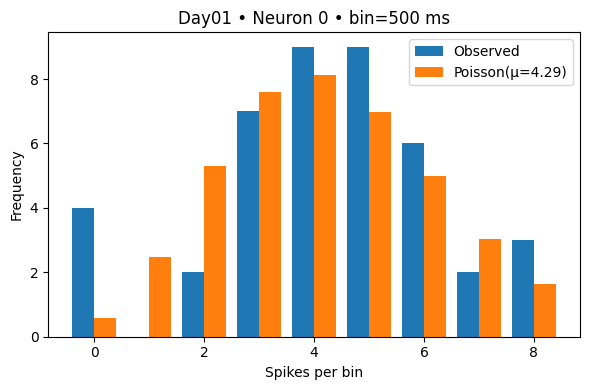

{'fano': 0.9934959349593496, 'chi2': 2.9857627473843498, 'p': 0.39382549338908324, 'lambda_hat': 4.285714285714286, 'counts': array([2, 2, 6, 5, 5, 3, 3, 6, 5, 4, 4, 5, 5, 5, 4, 4, 7, 6, 8, 6, 7, 4,
       5, 3, 3, 8, 4, 4, 4, 5, 6, 3, 4, 5, 8, 6, 3, 3, 0, 0, 0, 0])}

=== Poisson-ness by bin size ===
bin_ms | median Fano | % neurons p>0.05 | median λ
    50 |       0.665 |           20.0% |    0.420
   100 |       0.604 |            6.7% |    0.844
   200 |       0.738 |            6.7% |    1.695
   500 |       1.438 |           26.7% |    4.238
  1000 |       2.216 |           26.7% |    8.476


In [13]:
sys.path.insert(0, "/Users/nmt121/Desktop/Repositories/Motoneuron_Model")
from functions_analysis_online_control_exp.check_poisson import *

# pick the first file from your S1 mapping
first_session, first_file = get_first_file_from_session_map(session_files1)
path = os.path.join('/Users/nmt121/Desktop/DATA/S1/', first_file)

# load MU and run a single-neuron check
MU = load_mu_from_pickle(path)
res = evaluate_one_neuron(MU, fsamp=2048, bin_ms=500, neuron_idx=0, plot=True, session_label=first_session)
print(res)  # {'fano': ..., 'chi2': ..., 'p': ..., 'lambda_hat': ...}

# sweep multiple bin sizes and print a compact summary
summary = summarize_poisson_by_bins(MU, fsamp=2048, bin_list_ms=[50,100,200,500,1000])
print_poisson_summary(summary)


# EXP: Predict spike counts of motoneuron N with the rest of the spikes of the motoneuron pool 

/Users/nmt121/Desktop/Repositories/Motoneuron_Model/functions_analysis_online_control_exp/GLM_analysis_spikes_pred.py:178: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, order=unique_sessions,


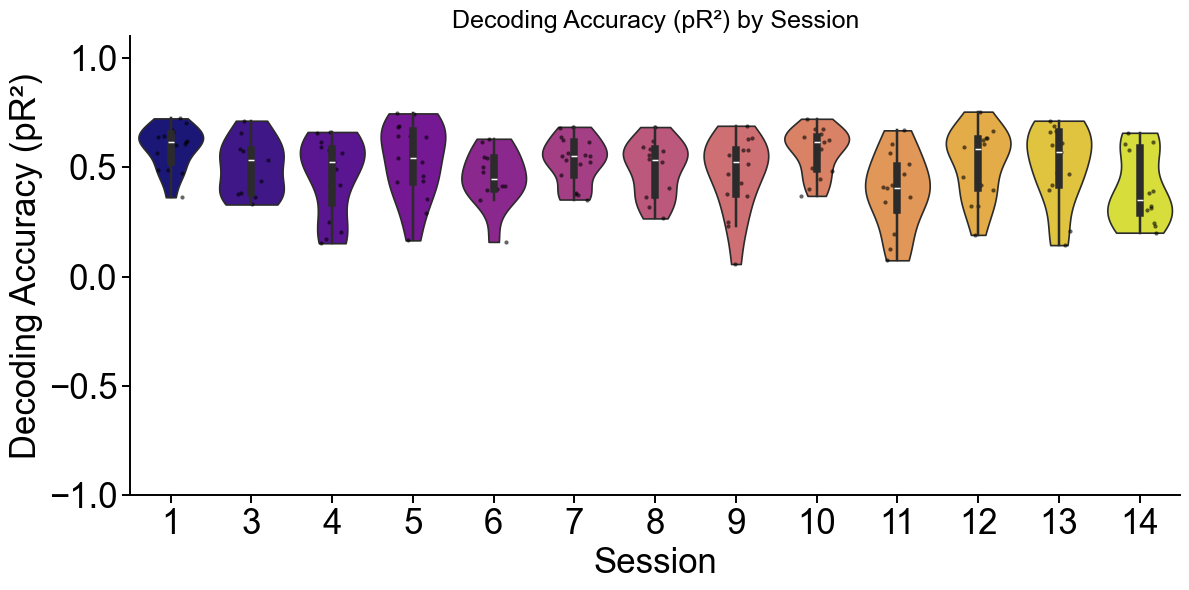

(<Figure size 640x480 with 0 Axes>,
 <Axes: title={'center': 'Decoding Accuracy (pR²) by Session'}, xlabel='Session', ylabel='Decoding Accuracy (pR²)'>)

<Figure size 640x480 with 0 Axes>

In [14]:
from functions_analysis_online_control_exp.GLM_analysis_spikes_pred import *
 
# Subject we are interested in studying
folder_path   = '/Users/nmt121/Desktop/DATA/S1/'
session_files = session_files1
fsamp = 2048
bin_size_ms = 500 # meets Poisson distribution
alpha_fixed = 0.1 #regularization
outer_kf = KFold(n_splits=10, shuffle=True, random_state=42)
 
# permissive per-fold guards
MIN_BINS_TEST   = 10   # In every cross-validation test fold, keep at least 10 time bins
MIN_NONZERO_TEST = 5   # In every test fold, make sure there are at least 5 bins where the target neuron actually fired (>0)
 
# Outputs
session_results = {}
session_predictions = {}
 
########## RUN GLM ##########
##############################

for session, pkl_files in session_files.items():
    session_pR2 = []
    trial_data_list = []
 
    for file in pkl_files:
        glm_data, data, mnpair = load_and_preprocess(file, folder_path, bin_size_ms, fsamp)
        trial_data_list.append(glm_data.T)  # (neurons, time_bins)
 
    concatenated_data = np.hstack(trial_data_list)  # (neurons, bins)
    num_neurons = concatenated_data.shape[0]
    # print(num_neurons)
 
    for target_idx in range(num_neurons):
        X_all, Y_all = create_glm_data(concatenated_data.T, target_idx)  # X: (bins, feats)
        if X_all is None or Y_all is None:
            continue
 
        #  ignore rare large counts that are not usual, using 99th percentile as cutoff
        y_max = max(2, int(np.floor(np.percentile(Y_all, 99))))
        keep_idx = np.where(Y_all <= y_max)[0]
 
        if keep_idx.size < 10 * MIN_BINS_TEST:
            # not enough bins left to support 10 splits with our minimum test bins
            continue
 
        X = X_all[keep_idx]
        Y = Y_all[keep_idx]
 
        fold_pR2s = []
        all_actual, all_predicted = [], []
 
        for train_idx, test_idx in outer_kf.split(X):

            if len(test_idx) < MIN_BINS_TEST:
                continue
 
            Xtr, Xte = X[train_idx], X[test_idx]
            Ytr, Yte = Y[train_idx], Y[test_idx]
 
            if (Yte > 0).sum() < MIN_NONZERO_TEST:
                continue  
 
            pipe = make_pipeline(StandardScaler(with_mean=True),PoissonRegressor(alpha=alpha_fixed, max_iter=1000))
            pipe.fit(Xtr, Ytr)
 
            Y_pred = pipe.predict(Xte)
            fold_pR2s.append(compute_pR2(Yte, Y_pred))
 
            all_actual.extend(Yte.tolist())
            all_predicted.extend(Y_pred.tolist())
 
        if fold_pR2s:
            session_pR2.append(np.nanmean(fold_pR2s))
            session_predictions.setdefault(session, []).append(
                {'target_idx': target_idx,
                 'actual': np.array(all_actual),
                 'pred':   np.array(all_predicted)}
            )
 
    if session_pR2:
        session_results[session] = session_pR2
 
# === Violin plot ===
plot_pr2_violin(session_results,out_path='/Users/nmt121/Desktop/Figures/GLM/GLM_good/pR2_violin1.pdf')
 
# # === Example time series ===
# for session in session_predictions.keys():
#     if not session_predictions[session]: continue
#     ap = session_predictions[session][0]
#     actual, pred, tidx = ap['actual'], ap['pred'], ap['target_idx']
#     plt.figure(figsize=(12,4)); plt.rcParams.update({'font.family':'Arial'})
#     plt.plot(actual, label="Actual ", alpha=0.9)
#     plt.plot(pred,   label="Predicted",          alpha=0.7)
#     plt.xlabel("Time bin (concatenated CV folds)", fontsize=14)
#     plt.ylabel("Spike count/bin", fontsize=14)
#     plt.title(f"Session {session} • Target neuron {tidx}", fontsize=14)
#     plt.legend(); plt.tight_layout(); plt.show()
 


### Median value of each day

In [ ]:
# sess_to_vals = {}
# for s, vals in session_results.items():
#     m = re.search(r'(\d+)', s)
#     short = str(int(m.group(1))) if m else s
#     sess_to_vals.setdefault(short, []).extend(vals)

# # Order sessions numerically
# ordered_labels = sorted(sess_to_vals.keys(), key=lambda x: int(x))
# medians1 = [np.nanmedian(sess_to_vals[lab]) for lab in ordered_labels]

# plt.figure(figsize=(10,4))
# plt.rcParams.update({'font.family':'Arial'})
# plt.plot(ordered_labels, medians1, marker='o', linewidth=2)
# plt.xlabel("Session (Day)", fontsize=16)
# plt.ylabel("Median pR²", fontsize=16)
# plt.ylim([-1, 1.1])
# plt.grid(alpha=0.25)
# plt.tight_layout()
# # plt.savefig('/Users/nmt121/Desktop/Figures/GLM/GLM_good/median7.pdf', dpi=300, bbox_inches='tight')
# plt.show()

# EXP: Predict spike counts of motoneuron N with the force of the motoneuron pool 

/Users/nmt121/Desktop/Repositories/Motoneuron_Model/functions_analysis_online_control_exp/GLM_analysis_force_pred.py:177: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, order=unique_sessions,


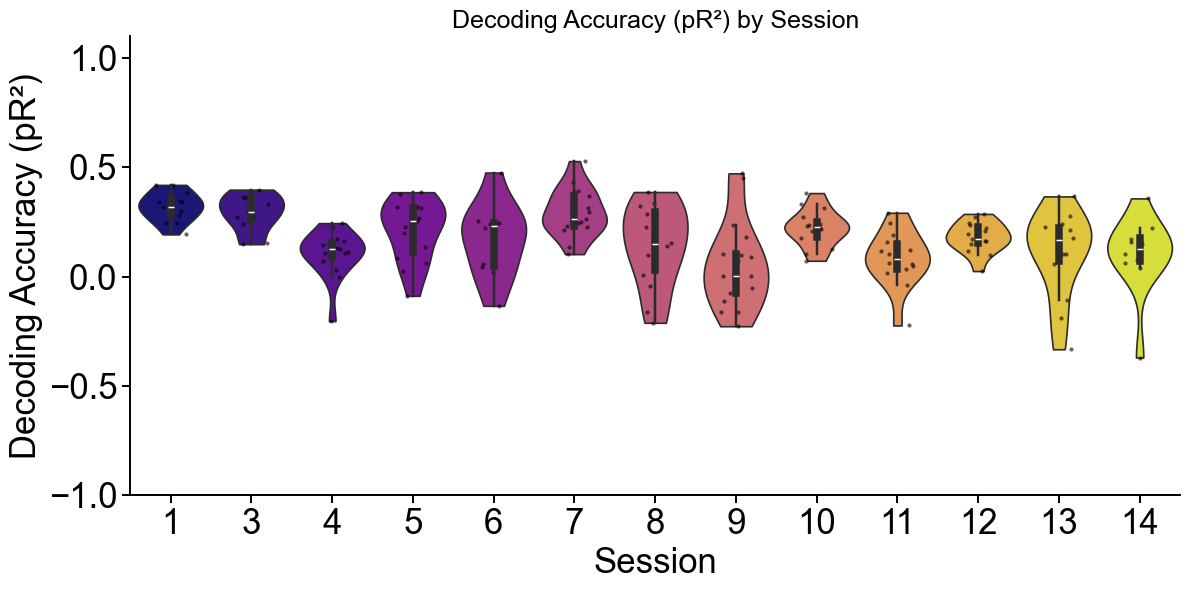

(<Figure size 640x480 with 0 Axes>,
 <Axes: title={'center': 'Decoding Accuracy (pR²) by Session'}, xlabel='Session', ylabel='Decoding Accuracy (pR²)'>)

<Figure size 640x480 with 0 Axes>

In [15]:
from functions_analysis_online_control_exp.GLM_analysis_force_pred import *

# Subject we are interested in studying
folder_path   = '/Users/nmt121/Desktop/DATA/S1/'
session_files = session_files1
fsamp         = 2048
bin_size_ms   = 500                
alpha_fixed   = 0.1                
outer_kf      = KFold(n_splits=10, shuffle=True, random_state=42)


MIN_BINS_TEST    = 10
MIN_NONZERO_TEST = 5


########## RUN GLM ##########
session_results = {}
session_predictions = {}

for session, pkl_files in session_files.items():
    session_pR2 = []
    force_trials, spike_trials = [], []

    # load & bin all trials
    for file in pkl_files:
        spikes, force, mnpair = preprocess_trial_force(file, folder_path, bin_size_ms, fsamp)
        if spikes is None or force is None:
            continue
        force_trials.append(force)   # (bins,)
        spike_trials.append(spikes)  # (neurons, bins)

    if not force_trials or not spike_trials:
        continue

    concatenated_force  = np.concatenate(force_trials, axis=0)   # (total_bins,)
    concatenated_spikes = np.hstack(spike_trials)                 # (neurons, total_bins)
    num_neurons = concatenated_spikes.shape[0]
    example_plotted = False

    # per neuron
    for neuron_idx in range(num_neurons):
        Y_full = concatenated_spikes[neuron_idx, :].astype(float)
        X_full, Y_full = create_force_glm_data(concatenated_force, Y_full)  # -> (bins, feats), (bins,)
        if X_full is None or Y_full is None:
            continue
        if np.sum(Y_full) < 20:
            continue

        # percentile trim (same logic)
        y_max = max(2, int(np.floor(np.percentile(Y_full, 99))))
        keep_idx = np.where(Y_full <= y_max)[0]
        if keep_idx.size < 10 * MIN_BINS_TEST:
            continue

        X = X_full[keep_idx]
        Y = Y_full[keep_idx]

        # outer CV (no inner grid)
        fold_pR2s = []
        all_actual, all_predicted = [], []

        for train_idx, test_idx in outer_kf.split(X):
            if len(test_idx) < MIN_BINS_TEST:
                continue
            Xtr, Xte = X[train_idx], X[test_idx]
            Ytr, Yte = Y[train_idx], Y[test_idx]
            if (Yte > 0).sum() < MIN_NONZERO_TEST:
                continue

            pipe = make_pipeline(
                StandardScaler(with_mean=True),
                PoissonRegressor(alpha=alpha_fixed, max_iter=1000)
            )
            pipe.fit(Xtr, Ytr)
            Y_pred = pipe.predict(Xte)

            fold_pR2s.append(compute_pR2(Yte, Y_pred))
            all_actual.extend(Yte.tolist())
            all_predicted.extend(Y_pred.tolist())



        if fold_pR2s:
            session_pR2.append(np.nanmean(fold_pR2s))
            session_predictions.setdefault(session, []).append(
                {'target_idx': neuron_idx,
                 'actual': np.array(all_actual),
                 'pred':   np.array(all_predicted)}
            )

    if session_pR2:
        session_results[session] = session_pR2

# === Violin plot ===
plot_pr2_violin(session_results,out_path='/Users/nmt121/Desktop/Figures/GLM/GLM_good/GLMforce1.pdf')


# SIM: Predict spike counts of motoneuron N with the rest of the spikes of the motoneuron pool 

In [ ]:
# Number of neurons per day per subject 
# counts_per_day_list = [15,11,15,15,12,17,14,17,16,14,15,15,12]
# counts_per_day_list = [9,11,11,11,9]
# counts_per_day_list = [11,11,11,9,10,10,10,9,10,11,11]
# counts_per_day_list = [15,13,14,13,13,13,11,11,12,14]
# counts_per_day_list = [13,13,16,15,14,18,15,11,16,12,18,15,13]
# counts_per_day_list = [14, 13, 12, 15, 12, 11, 13, 12, 15, 10]

Sessions: ['Day01', 'Day02', 'Day03', 'Day04', 'Day05', 'Day06', 'Day07', 'Day08', 'Day09', 'Day10']
Counts per session: [14, 13, 12, 15, 12, 11, 13, 12, 15, 10]


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_88951/4201431762.py:208: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, order=unique_sessions,


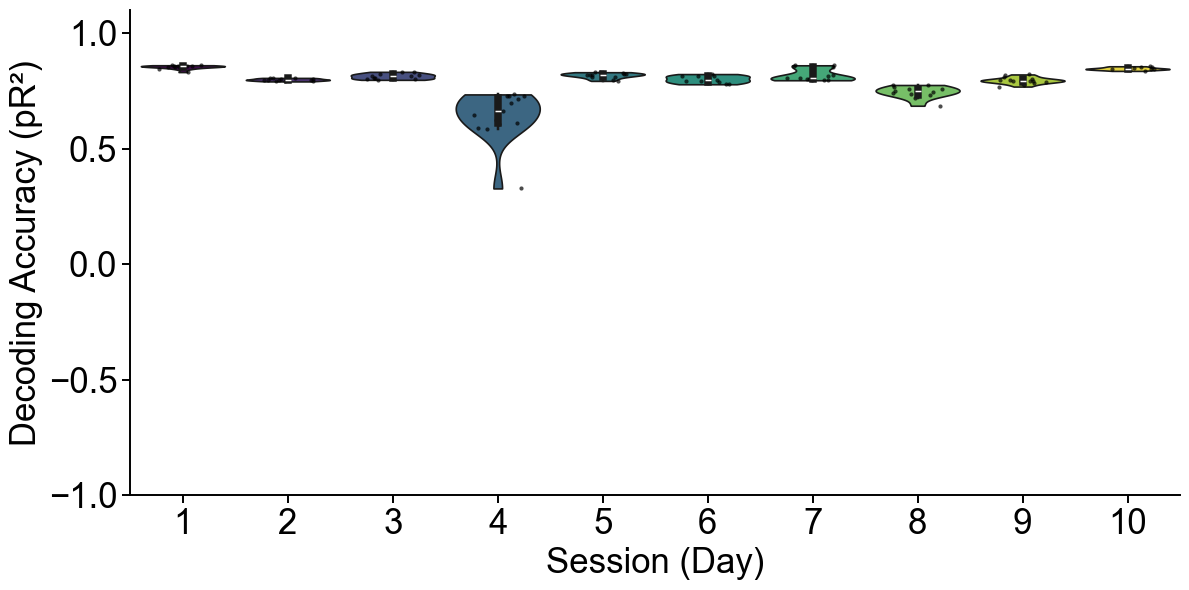

In [ ]:
from functions_analysis_online_control_exp.GLM_analysis_spikes_SIMS import *


base_dir      = '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S7_alltrials'
h5_key        = 'spike_array'  
fsamp         = 20000           
bin_size_ms   = 500             
alpha_fixed   = 0.1
outer_kf      = KFold(n_splits=10, shuffle=True, random_state=42)

MIN_BINS_TEST = 10
MIN_NONZERO_TEST = 5



# plotting
SHOW_TS_PER_SESSION = 5
# SAVE_FIRST_TS_PATH  = '/Users/nmt121/Desktop/Figures/GLM/GLM_Good/trial4.pdf'

random.seed(42)  # reproducibility


########## Organize data ##########

session_files = build_session_files(base_dir)
sessions_sorted = sorted(session_files.keys(), key=day_sort_key)

# Map day name -> requested count, using your list order
counts_by_session = {}
for i, s in enumerate(sessions_sorted):
    if i < len(counts_per_day_list):
        counts_by_session[s] = counts_per_day_list[i]
    else:
        counts_by_session[s] = counts_per_day_list[-1]  # fallback to last value if more days than numbers

print("Sessions:", sessions_sorted)
print("Counts per session:", [counts_by_session[s] for s in sessions_sorted])

########## RUN GLM ##########

session_results = {}
session_predictions = {}

for session in sessions_sorted:
    files = session_files[session]
    session_pR2 = []
    trial_spk_list = []

    # load & bin all trials for this day/session
    for fpath in files:
        MU_sn = load_jld2_h5(fpath, key=h5_key)                         # (samples, neurons)
        b_spk = bin_spikes_samples_by_neurons(MU_sn, bin_size_ms, fsamp) # (neurons, bins)
        if b_spk is None:
            continue
        trial_spk_list.append(b_spk)

    if not trial_spk_list:
        continue

    concatenated_spikes = np.hstack(trial_spk_list)   # (neurons, total_bins)
    num_neurons = concatenated_spikes.shape[0]
    spikes_T = concatenated_spikes.T                  # (bins x neurons)

    # --- pick per-day random subset of neurons ---
    n_desired = min(counts_by_session.get(session, 10), num_neurons)
    neuron_indices = list(range(num_neurons))
    random.shuffle(neuron_indices)
    subset_indices = neuron_indices[:n_desired]

    for target_idx in subset_indices:
        X_all, Y_all = create_glm_data_pop(spikes_T, target_idx)

        # Trim extreme counts (adaptive 99th percentile)
        y_max = max(2, int(np.floor(np.percentile(Y_all, 99))))
        keep_idx = np.where(Y_all <= y_max)[0]
        if keep_idx.size < 10 * MIN_BINS_TEST:
            continue

        X = X_all[keep_idx]
        Y = Y_all[keep_idx]

        fold_pR2s = []
        all_actual, all_predicted = [], []

        for train_idx, test_idx in outer_kf.split(X):
            if len(test_idx) < MIN_BINS_TEST:    continue
            Xtr, Xte = X[train_idx], X[test_idx]
            Ytr, Yte = Y[train_idx], Y[test_idx]
            if (Yte > 0).sum() < MIN_NONZERO_TEST:  continue

            pipe = make_pipeline(
                StandardScaler(with_mean=True),
                PoissonRegressor(alpha=alpha_fixed, max_iter=1000)
            )
            pipe.fit(Xtr, Ytr)
            Y_pred = pipe.predict(Xte)

            fold_pR2s.append(compute_pR2(Yte, Y_pred))
            all_actual.extend(Yte.tolist())
            all_predicted.extend(Y_pred.tolist())

        if fold_pR2s:
            session_pR2.append(np.nanmean(fold_pR2s))
            session_predictions.setdefault(session, []).append(
                {'target_idx': target_idx,
                 'actual': np.array(all_actual),
                 'pred':   np.array(all_predicted)}
            )

    if session_pR2:
        session_results[session] = session_pR2


# === Violin plot ===
# plot_pr2_violin(session_results,out_path='/Users/nmt121/Desktop/Figures/GLM/GLM_good/GLMforce1.pdf')



# SIM: Predict spike counts of motoneuron N with the force of the motoneuron pool 

Days: ['Day01', 'Day02', 'Day03', 'Day04', 'Day05', 'Day06', 'Day07', 'Day08', 'Day09', 'Day10']
Requested neurons/day: [14, 13, 12, 15, 12, 11, 13, 12, 15, 10]
[Day01] used neurons: 14, pR2 count: 14
[Day02] used neurons: 13, pR2 count: 13
[Day03] used neurons: 12, pR2 count: 12
[Day04] used neurons: 0, pR2 count: 0
[Day05] used neurons: 12, pR2 count: 12
[Day06] used neurons: 11, pR2 count: 11
[Day07] used neurons: 13, pR2 count: 13
[Day08] used neurons: 12, pR2 count: 12
[Day09] used neurons: 15, pR2 count: 15
[Day10] used neurons: 10, pR2 count: 10


/var/folders/xt/z8_l6n9d1wv6vpcb5vdsp1dr0000gq/T/ipykernel_88951/1327180297.py:260: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(x=all_labels, y=all_pR2s, order=unique_sessions,


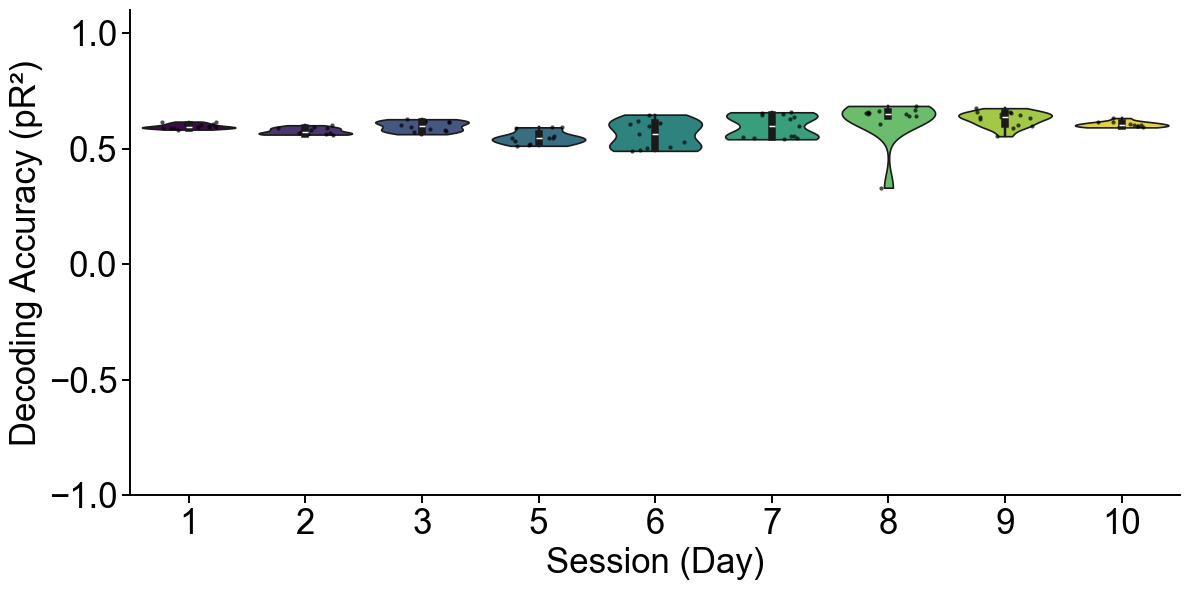

In [ ]:
from functions_analysis_online_control_exp.GLM_analysis_force_SIMS import *

spike_base_dir = '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Spikes/Simulations_with_force_as_input/DR_S7_alltrials'
force_base_dir = '/Users/nmt121/Desktop/Repositories/Motoneuron_Model/Data_MN_Model/Data_final/Scaled_force/S7_alltrials'

h5_key          = 'spike_array'   
fsamp_spk       = 20000           
fsamp_force     = 2048           
bin_size_ms     = 500             
alpha_fixed     = 0.1
outer_kf        = KFold(n_splits=10, shuffle=True, random_state=42)

MIN_BINS_TEST    = 10
MIN_NONZERO_TEST = 5
SHOW_TS_PER_SESSION = 5

SAVE_VIOLIN_PATH   = '/Users/nmt121/Desktop/Figures/GLM/GLM_good/sim_7_force_NO_LAG.pdf'


# --------------------
# Pair trials, sort days, map counts
# --------------------
spike_map = list_trials_spike(spike_base_dir)   # {DayXX: {DayXX_trialYY: path}}
force_map = list_trials_force(force_base_dir)   # {DayXX: {DayXX_trialYY: path}}

days = sorted(set(spike_map.keys()) & set(force_map.keys()), key=day_num)

# Map your list to the discovered days in order.
# If the list is shorter than the number of days, repeat the last value.
# If longer, extra entries are ignored.
counts_by_day = {
    day: (counts_per_day_list[i] if i < len(counts_per_day_list) else counts_per_day_list[-1])
    for i, day in enumerate(days)
}

# print("Days:", days)
# print("Requested neurons/day:", [counts_by_day[d] for d in days])

# --------------------
# Run GLM (NO LAGS)
# --------------------
session_results = {}
session_predictions = {}

for day in days:
    trials = sorted(set(spike_map[day].keys()) & set(force_map[day].keys()))
    if not trials:
        continue

    session_pR2 = []
    trial_spk_list, trial_force_list = [], []

    for tkey in trials:
        sp_path = spike_map[day][tkey]
        fo_path = force_map[day][tkey]

        MU_sn = load_spikes(sp_path, key=h5_key)                              # (samples, neurons)
        F     = load_force_npy(fo_path)                                       # (samples,)

        b_spk = bin_spikes_samples_by_neurons(MU_sn, bin_size_ms, fsamp_spk)  # (neurons, bins)
        b_for = bin_force(F, bin_size_ms, fsamp_force)                        # (bins,)

        if b_spk is None or b_for is None:
            continue

        nb = min(b_spk.shape[1], b_for.shape[0])
        if nb < MIN_BINS_TEST:
            continue

        trial_spk_list.append(b_spk[:, :nb])
        trial_force_list.append(b_for[:nb])

    if not trial_spk_list:
        print(f"[{day}] no usable trials after bin/align.")
        continue

    concatenated_spikes = np.hstack(trial_spk_list)            # (neurons, total_bins)
    concatenated_force  = np.concatenate(trial_force_list, 0)  # (total_bins,)
    if concatenated_force.shape[0] != concatenated_spikes.shape[1]:
        m = min(concatenated_spikes.shape[1], concatenated_force.shape[0])
        concatenated_spikes = concatenated_spikes[:, :m]
        concatenated_force  = concatenated_force[:m]

    # NO LAG: X is just the current force bin
    X_force = concatenated_force.reshape(-1, 1)  # (T, 1)
    spikes_T = concatenated_spikes.T            # (T x neurons)
    num_neurons = spikes_T.shape[1]

    # per-day random subset of neurons (no random seed -> different each run)
    n_desired = min(counts_by_day.get(day, 10), num_neurons)
    neuron_indices = list(range(num_neurons))
    random.shuffle(neuron_indices)
    subset_indices = neuron_indices[:n_desired]

    for target_idx in subset_indices:
        Y_all = spikes_T[:, target_idx].astype(float)
        X_all = X_force.astype(float)

        # Trim extreme counts
        y_max = max(2, int(np.floor(np.percentile(Y_all, 99))))
        keep_idx = np.where(Y_all <= y_max)[0]
        if keep_idx.size < 10 * MIN_BINS_TEST:
            continue

        X = X_all[keep_idx]
        Y = Y_all[keep_idx]

        fold_pR2s = []
        all_actual, all_predicted = [], []

        for train_idx, test_idx in outer_kf.split(X):
            if len(test_idx) < MIN_BINS_TEST:            continue
            Xtr, Xte = X[train_idx], X[test_idx]
            Ytr, Yte = Y[train_idx], Y[test_idx]
            if (Yte > 0).sum() < MIN_NONZERO_TEST:       continue

            pipe = make_pipeline(
                StandardScaler(with_mean=True),
                PoissonRegressor(alpha=alpha_fixed, max_iter=1000)
            )
            pipe.fit(Xtr, Ytr)
            Y_pred = pipe.predict(Xte)

            fold_pR2s.append(compute_pR2(Yte, Y_pred))
            all_actual.extend(Yte.tolist())
            all_predicted.extend(Y_pred.tolist())

        if fold_pR2s:
            session_pR2.append(np.nanmean(fold_pR2s))
            session_predictions.setdefault(day, []).append(
                {'target_idx': target_idx,
                 'actual': np.array(all_actual),
                 'pred':   np.array(all_predicted)}
            )

    if session_pR2:
        session_results[day] = session_pR2
    print(f"[{day}] used neurons: {len(session_predictions.get(day, []))}, "
          f"pR2 count: {len(session_results.get(day, []))}")
    
    
    

# === Violin plot ===
# plot_pr2_violin(session_results,out_path='/Users/nmt121/Desktop/Figures/GLM/GLM_good/GLMforce1.pdf')
